# Spatial summary selection

How a building's depth is read off the depth grid: the max, mean, median or 90th percentile of the cells its footprint touches, or the cell holding its centroid. Each panel shows building depth from the surveyed July 2021 depths against the post-event placard damage class, with the Pearson correlation (r) between the two. The mean gives the strongest association and is the summary used throughout.

The data come from `July2021Validation.placard_building_depths()`, the same buildings and depths `main.py calibrate` scores.

In [1]:
import os, sys, logging

REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, REPO_ROOT)
logging.disable(logging.INFO)

# Drop any project modules a long-running kernel already imported, so this cell
# always runs the code as it is on disk now (Python never reloads a changed file
# on its own -- that is what raised "cannot import name 'pearson'").
for name in [n for n in sys.modules if n == "modules" or n.startswith("modules.")]:
    del sys.modules[name]

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from modules.exposure_module.exposure_module import SPATIAL_SUMMARIES
from modules.validation_module.july_2021_validation import July2021Validation
from modules.validation_module.metrics import pearson

FIG_DIR = os.path.join(REPO_ROOT, "out")
CHOSEN = "mean"                        # named in bold; colour is the same for every summary
LABELS = {"max": "Max", "mean": "Mean", "median": "Median", "p90": "90th percentile", "centroid": "Centroid cell"}
DAMAGE_LABELS = {0: "None", 1: "Slight", 2: "Moderate", 3: "Severe"}

# Same print-first style as the paper figures in westport/notebooks/results_analysis.ipynb.
# FIG_WIDTH_IN is the one size knob: type, line weights and markers all scale with it.
# 7.2 in is a journal's full double-column width; the default is that layout enlarged
# for reading on screen, and reduces to the print version by setting FIG_WIDTH_IN = 7.2.
FIG_WIDTH_IN = 13.0
_SCALE = FIG_WIDTH_IN / 7.2
BASE_FONT_PT = 8 * _SCALE
FILL, EDGE = "#C6DBEF", "#08519C"     # light fill under a darker outline: holds in greyscale print

plt.rcParams.update({
    # Serif, as in the other paper figures. Liberation Serif has Times New Roman's
    # metrics, so the layout is the same wherever Times is installed instead.
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"],
    # Bold panel letters go through mathtext; point it at the same serif face so
    # they do not fall back to DejaVu Sans.
    "mathtext.fontset": "custom",
    "mathtext.rm": "serif",
    "mathtext.it": "serif:italic",
    "mathtext.bf": "serif:bold",
    "mathtext.cal": "serif",
    "mathtext.sf": "serif",
    "font.size": BASE_FONT_PT,
    "axes.titlesize": BASE_FONT_PT + 1,
    "axes.labelsize": BASE_FONT_PT + 1,
    "xtick.labelsize": BASE_FONT_PT - 1,
    "ytick.labelsize": BASE_FONT_PT - 1,
    "legend.fontsize": BASE_FONT_PT - 1,
    # Labels, ticks and frame in black, set explicitly so a kernel that ran an
    # earlier style does not leave them grey.
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "xtick.labelcolor": "black",
    "ytick.labelcolor": "black",
    "axes.linewidth": 0.6 * _SCALE,
    "xtick.major.width": 0.6 * _SCALE,
    "ytick.major.width": 0.6 * _SCALE,
    "xtick.major.size": 2.5 * _SCALE,
    "ytick.major.size": 2.5 * _SCALE,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.bbox": "tight",
})


def style_axes(ax, grid_axis="y"):
    ax.grid(True, axis=grid_axis, color="0.85", lw=0.4 * _SCALE, alpha=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(direction="out")


def panel_title(ax, letter, name, chosen=False, pad=14):
    """Bold panel letter and name, the way the paper's other figures label panels."""
    name = f"$\\bf{{{name}}}$" if chosen else name
    ax.set_title(f"$\\bf{{({letter})}}$ {name}", fontsize=BASE_FONT_PT + 1,
                 pad=pad * _SCALE, loc="left")

In [81]:
# Per-building depths under every summary, and each summary's Pearson correlation
# with the damage class.
calibration = July2021Validation()
calibration.scenario_id = 0
buildings = calibration.placard_building_depths()

damage = buildings["DamageNb"].astype(int).to_numpy()
classes = sorted(np.unique(damage))
r = pd.Series({s: pearson(buildings[s], damage) for s in SPATIAL_SUMMARIES}, name="pearson")

counts = pd.Series(damage).value_counts().sort_index()
print(f"{len(buildings):,} buildings; per damage class:", counts.to_dict())
r.round(3)

2,247 buildings; per damage class: {0: 1598, 1: 179, 2: 356, 3: 114}


max         0.657
mean        0.686
median      0.684
p90         0.672
centroid    0.662
Name: pearson, dtype: float64

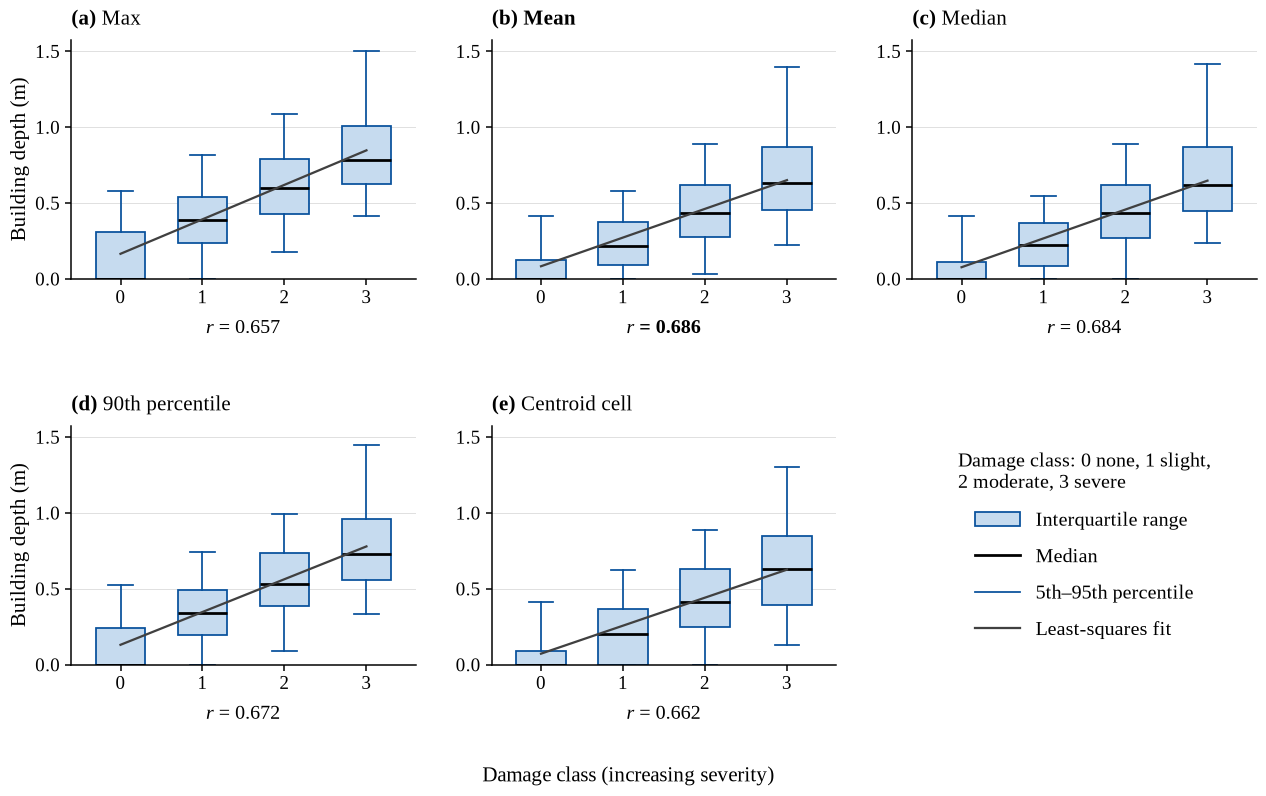

In [82]:
# Figure 1: building depth by damage class, one panel per spatial summary, in two
# rows of three so each panel stays readable at full page width; the sixth slot
# holds the key. Whiskers run to the 5th and 95th percentiles and individual
# buildings beyond them are not drawn: with 1,598 undamaged buildings the outliers
# form solid columns that hide the boxes.
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

WHISKERS = (5, 95)
FIT_COLOUR = "0.25"

fig, grid = plt.subplots(2, 3, figsize=(FIG_WIDTH_IN, FIG_WIDTH_IN * 0.62), sharey=True)
axes = grid.ravel()
for i, (ax, s) in enumerate(zip(axes, SPATIAL_SUMMARIES)):
    bp = ax.boxplot(
        [buildings[s][damage == c] for c in classes], positions=classes, widths=0.6,
        whis=WHISKERS, patch_artist=True, showfliers=False,
        medianprops=dict(color="black", lw=1.1 * _SCALE),
        whiskerprops=dict(color=EDGE, lw=0.7 * _SCALE),
        capprops=dict(color=EDGE, lw=0.7 * _SCALE),
    )
    for patch in bp["boxes"]:
        patch.set_facecolor(FILL)
        patch.set_edgecolor(EDGE)
        patch.set_linewidth(0.7 * _SCALE)

    # Least-squares line of building depth on damage class, fitted to every
    # building: the straight line the panel's Pearson r measures the fit of.
    slope, intercept = np.polyfit(damage, buildings[s], 1)
    ax.plot([classes[0], classes[-1]], [intercept + slope * classes[0], intercept + slope * classes[-1]],
            color=FIT_COLOUR, lw=0.9 * _SCALE, zorder=4)

    panel_title(ax, chr(97 + i), LABELS[s], chosen=(s == CHOSEN), pad=6)
    ax.set_xticks(classes)
    ax.set_xlim(-0.6, classes[-1] + 0.6)
    ax.tick_params(labelleft=True)
    style_axes(ax)
    # The panel's Pearson correlation with damage class, under its tick labels.
    ax.text(0.5, -0.17, f"$r$ = {r[s]:.3f}", transform=ax.transAxes,
            ha="center", va="top", fontsize=BASE_FONT_PT,
            fontweight="bold" if s == CHOSEN else "normal")

for ax in grid[:, 0]:
    ax.set_ylabel("Building depth (m)")
grid[0, 0].set_ylim(bottom=0)

# The free sixth slot carries the key, so the caption need not describe the marks.
key = axes[len(SPATIAL_SUMMARIES)]
key.axis("off")
key.legend(
    handles=[
        Patch(facecolor=FILL, edgecolor=EDGE, linewidth=0.7 * _SCALE, label="Interquartile range"),
        Line2D([], [], color="black", lw=1.1 * _SCALE, label="Median"),
        Line2D([], [], color=EDGE, lw=0.7 * _SCALE, label="5th–95th percentile"),
        Line2D([], [], color=FIT_COLOUR, lw=0.9 * _SCALE, label="Least-squares fit"),
    ],
    loc="center", frameon=False, fontsize=BASE_FONT_PT, handlelength=2.2, labelspacing=0.9,
    title="Damage class: 0 none, 1 slight,\n2 moderate, 3 severe", title_fontsize=BASE_FONT_PT,
)
fig.supxlabel("Damage class (increasing severity)", fontsize=BASE_FONT_PT + 1)
fig.tight_layout(h_pad=2.5, w_pad=1.5)
for ext in ("pdf", "png"):
    fig.savefig(os.path.join(FIG_DIR, f"fig_spatial_summary_depth_by_damage.{ext}"), dpi=600)
plt.show()

In [2]:
# Figure 2: hourly MAE (all and wet buildings), wet bias, hit rate and CSI by flood driver.
#
# One box per driver, pooling every hour of every event in that driver group
# (from per_timestep_metrics.csv). The grouping is the one in
# westport/notebooks/results_analysis.ipynb (EVENT_GROUPS), so both papers split
# the test events the same way. Box style as there: light blue box, darker
# outline, black median line, whiskers at 1.5 x IQR, hourly outliers hollow.
from modules.lib import VALIDATION_RESULTS_DIR

# Results folder of each model (main.py validate --model ...); MODEL picks the one
# the figures and table below are made for. The 1D-CNN benchmark's files get a
# _cnn1d suffix so they never overwrite the surrogate's.
RUN_CONFIGS = {"flow_matching": "mean_M10_K1_hours12_decode5_seed41",
               "cnn1d": "mean_cnn1d_hours12"}
MODEL = "flow_matching"
RUN_CONFIG = RUN_CONFIGS[MODEL]
FILE_SUFFIX = "" if MODEL == "flow_matching" else f"_{MODEL}"
# Warm-up: hours dropped from the start of every event, here and in Figures 3-4.
# The simulation starts from a dry initial state while the surrogate has no such
# state and already floods houses at the first step (4,265 in event 17), so the
# opening hours score the cold start, not the forecast. SKIP_WARM_UP = False
# keeps every step.
SKIP_WARM_UP = True
WARM_UP_HOURS = 4
SKIP_FIRST_STEPS = WARM_UP_HOURS if SKIP_WARM_UP else 0
EVENT_GROUPS = {
    "River-dominated":   [3, 43, 64, 83],
    "Compound":          [13, 37, 54, 91, 93],
    "Coastal-dominated": [17, 57, 106],
}
SHOW_OUTLIERS = True
SHORT_NAMES = {"River-dominated": "River", "Compound": "Compound", "Coastal-dominated": "Coastal"}

per_timestep = pd.read_csv(os.path.join(VALIDATION_RESULTS_DIR, RUN_CONFIG, "per_timestep_metrics.csv"))
# An event run twice under the same configuration appends its hours twice;
# keep the latest run of each hour.
per_timestep = per_timestep.drop_duplicates(["scenario_id", "time_step"], keep="last")
per_timestep = per_timestep[per_timestep["time_step"] >= SKIP_FIRST_STEPS]
regime_of = {event: regime for regime, events in EVENT_GROUPS.items() for event in events}
per_timestep["regime"] = per_timestep["scenario_id"].map(regime_of)
missing = sorted(set(per_timestep.loc[per_timestep["regime"].isna(), "scenario_id"]))
if missing:
    print("scenarios in no driver group, left out:", missing)

# MAE and bias (forecast - observed) of the ensemble-median depth over all
# buildings and over the observed-wet ones (the buildings crps / crps_wet average
# over; bias only over the wet ones), and the hourly hit rate and CSI. Top row:
# MAE, MAE_wet, hit rate; bottom row: Bias_wet under MAE_wet, CSI under hit
# rate. Subscript t: each box value is one hour's score.
# (grid position, column, y label, which way is better)
panels = [((0, 0), "mae", "MAE$_{t}$ (m)", "lower is better"),
          ((0, 1), "mae_wet", "MAE$_{\\mathrm{wet},\\,t}$ (m)", "lower is better"),
          ((0, 2), "hit_rate", "Hit rate$_{t}$", "higher is better"),
          ((1, 1), "bias_wet", "Bias$_{\\mathrm{wet},\\,t}$ (m)", "0 is unbiased"),
          ((1, 2), "csi", "CSI$_{t}$", "higher is better")]
regimes = list(EVENT_GROUPS)

fig, grid = plt.subplots(2, 3, figsize=(FIG_WIDTH_IN, FIG_WIDTH_IN * 0.66))
grid[1, 0].set_axis_off()
for i, (cell, column, label, better) in enumerate(panels):
    ax = grid[cell]
    data = [per_timestep.loc[per_timestep["regime"] == r, column].dropna().to_numpy() for r in regimes]
    positions = [p for p, d in enumerate(data) if len(d)]
    bp = ax.boxplot(
        [d for d in data if len(d)], positions=positions, widths=0.55, patch_artist=True,
        showfliers=SHOW_OUTLIERS,
        medianprops=dict(color="black", lw=1.1 * _SCALE),
        whiskerprops=dict(color=EDGE, lw=0.7 * _SCALE),
        capprops=dict(color=EDGE, lw=0.7 * _SCALE),
        flierprops=dict(marker="o", markersize=1.6 * _SCALE, markerfacecolor="none",
                        markeredgecolor=EDGE, markeredgewidth=0.4 * _SCALE, alpha=0.55),
    )
    for patch in bp["boxes"]:
        patch.set_facecolor(FILL)
        patch.set_edgecolor(EDGE)
        patch.set_linewidth(0.7 * _SCALE)

    ax.set_xticks(range(len(regimes)))
    ax.set_xticklabels([f"{SHORT_NAMES[r]}\n(n = {len(d)})" for r, d in zip(regimes, data)],
                       fontsize=BASE_FONT_PT - 1.5)
    # Driver label once per column, on its lowest panel.
    if cell[0] == 1 or cell == (0, 0):
        ax.set_xlabel("Flood driver")
    ax.set_xlim(-0.6, len(regimes) - 0.4)
    ax.set_ylabel(f"{label}\n({better})")
    if column in ("hit_rate", "csi"):
        ax.set_ylim(top=1.02)
    if column.startswith("bias"):
        ax.axhline(0, color="0.35", lw=0.6 * _SCALE, zorder=0)
    panel_title(ax, chr(97 + i), "", pad=6)
    style_axes(ax)

fig.tight_layout(h_pad=2.5, w_pad=2)
for ext in ("pdf", "png"):
    fig.savefig(os.path.join(FIG_DIR, f"fig_mae_bias_hit_rate_csi_by_driver{FILE_SUFFIX}.{ext}"), dpi=600)
plt.show()


In [3]:
# Per-house scores over each whole event, without its first SKIP_FIRST_STEPS hours.
#
# Rebuilt from building_hourly_depth.csv (every house's depth every hour: the
# hydrodynamic simulation's observed_depth and the surrogate's ensemble-median
# depth_median) with the same functions and rules as
# DepthValidation.score_event, which wrote building_event_metrics.csv from all
# the hours. With SKIP_FIRST_STEPS = 0 this reproduces that file. Peak = highest
# hour of each series; onset = first exposed hour (depth > 0.05 m); a house is
# exposed over the event if its peak is; timing only where both sides expose it.
from modules.exposure_module.exposure_module import is_exposed
from modules.validation_module.metrics import hours_between, onset_times, peaks

def building_event_scores(run_config, events=None, forecast_columns="depth_median"):
    """Per-house scores of one run configuration's results folder, one row per
    house per event (optionally only ``events``), without each event's first
    SKIP_FIRST_STEPS hours. ``forecast_columns``: the forecast depth scored, the
    ensemble median by default; a list of columns (e.g. the member percentiles
    depth_min, depth_p25, depth_p75, depth_max) scores each one as a single
    forecast from one read of the file and returns {column: scores}."""
    columns = [forecast_columns] if isinstance(forecast_columns, str) else list(forecast_columns)
    hourly_depth = pd.read_csv(
        os.path.join(VALIDATION_RESULTS_DIR, run_config, "building_hourly_depth.csv"),
        usecols=["scenario_id", "valid_time", "building_id", "observed_depth", *columns])
    if events is not None:
        hourly_depth = hourly_depth[hourly_depth["scenario_id"].isin(events)]
    # Repeated runs of an event append its hours again; keep the latest.
    hourly_depth = hourly_depth.drop_duplicates(["scenario_id", "valid_time", "building_id"], keep="last")

    event_tables = {column: [] for column in columns}
    for scenario_id, event in hourly_depth.groupby("scenario_id"):
        # (times, buildings) per side; hours in order, the first ones dropped.
        observed = event.pivot(index="valid_time", columns="building_id", values="observed_depth").sort_index()
        observed = observed.iloc[SKIP_FIRST_STEPS:]
        times = pd.to_datetime(observed.index)
        observed_peak, observed_peak_time = peaks(observed.to_numpy(), times)
        observed_onset = onset_times(observed.to_numpy(), times)
        observed_exposed = is_exposed(observed_peak)
        for column in columns:
            forecast = event.pivot(index="valid_time", columns="building_id", values=column).sort_index()
            forecast = forecast.iloc[SKIP_FIRST_STEPS:]
            forecast_peak, forecast_peak_time = peaks(forecast.to_numpy(), times)
            forecast_exposed = is_exposed(forecast_peak)
            both = observed_exposed & forecast_exposed
            event_tables[column].append(pd.DataFrame({
                "scenario_id": scenario_id,
                "building_id": observed.columns,
                "observed_peak_depth": observed_peak,
                "forecast_peak_depth": forecast_peak,
                "peak_depth_error": forecast_peak - observed_peak,
                "peak_time_error_h": np.where(both, hours_between(forecast_peak_time, observed_peak_time), np.nan),
                "onset_error_h": np.where(both, hours_between(onset_times(forecast.to_numpy(), times),
                                                              observed_onset), np.nan),
                "exposure_outcome": np.select([both, observed_exposed, forecast_exposed],
                                              ["hit", "miss", "false_alarm"], default="correct_negative"),
            }))
    scores = {column: pd.concat(tables, ignore_index=True) for column, tables in event_tables.items()}
    return scores[forecast_columns] if isinstance(forecast_columns, str) else scores


building_events = building_event_scores(RUN_CONFIG)
building_events["regime"] = building_events["scenario_id"].map(regime_of)
print(f"first {SKIP_FIRST_STEPS} hour(s) of each event dropped;",
      building_events["exposure_outcome"].value_counts().to_dict())

first 4 hour(s) of each event dropped; {'correct_negative': 35306, 'hit': 26599, 'false_alarm': 4153, 'miss': 614}


In [4]:
# Detection of inundated buildings that are in the computational domain (5556) for an individual event.
# Timing error based on the first time that was inundated in the reference model vs our model vs 1dcnn model

# Need a table with Hit Rate, CSI and Average timing error +- std (per building)
#
# For each test event: each house in the computational domain is exposed in a
# run if its depth exceeds 0.05 m at any hour after the warm-up
# (exposure_outcome, from building_event_scores). Hit rate = hits / (hits +
# misses); CSI = hits / (hits + misses + false alarms). Onset error = first
# exposed hour in the model minus the first in the simulation (the reference),
# per house, over the hits: mean +- SD across houses (positive = model floods
# it late). Events in driver order, as in the figures.
#
# Flow matching is shown at five percentiles of its ensemble, from
# percentile_event_metrics.csv (same warm-up): each percentile's depth series
# scored as a single forecast. Min = warn only if every member floods the house,
# Max = if any member does; the median is the forecast everywhere else, and the
# only one with an arrival time.
MODEL_LABELS = {"flow_matching": "Flow matching", "cnn1d": "1D-CNN"}
events = [event for regime in regimes for event in EVENT_GROUPS[regime]]

columns = {}
model_scores = {}   # per-house scores of each model, kept for the onset box plot below
for model, run_config in RUN_CONFIGS.items():
    scores = model_scores[model] = building_event_scores(run_config, events=events)
    for event, event_scores in scores.groupby("scenario_id"):
        outcome = event_scores["exposure_outcome"]
        hits, misses = (outcome == "hit").sum(), (outcome == "miss").sum()
        false_alarms = (outcome == "false_alarm").sum()
        onset = event_scores["onset_error_h"].dropna()
        label = "FM P50" if model == "flow_matching" else MODEL_LABELS[model]
        columns.setdefault((label, "Hit rate"), {})[event] = hits / (hits + misses) if hits + misses else np.nan
        columns.setdefault((label, "CSI"), {})[event] = hits / (hits + misses + false_alarms) if hits + misses + false_alarms else np.nan
        columns.setdefault((label, "\u0394t_arr (h)"), {})[event] = (
            f"{onset.mean():+.2f} \u00b1 {onset.std():.2f}" if len(onset) > 1 else "n/a")
        columns.setdefault(("Simulation", "Flooded houses"), {})[event] = hits + misses

# The other flow-matching percentiles, from the validation's percentile file.
FM_PERCENTILE_GROUPS = {"min": "FM P0", "p25": "FM P25", "median": "FM P50",
                        "p75": "FM P75", "max": "FM P100"}
fm_percentiles = pd.read_csv(os.path.join(VALIDATION_RESULTS_DIR, RUN_CONFIGS["flow_matching"],
                                          "percentile_event_metrics.csv"))
fm_percentiles = fm_percentiles.drop_duplicates(["scenario_id", "percentile"], keep="last")
assert (fm_percentiles["warm_up_h"] == SKIP_FIRST_STEPS).all(), "percentile metrics use a different warm-up"
for row in fm_percentiles[fm_percentiles["percentile"] != "median"].itertuples():
    group = FM_PERCENTILE_GROUPS[row.percentile]
    columns.setdefault((group, "Hit rate"), {})[row.scenario_id] = row.hit_rate
    columns.setdefault((group, "CSI"), {})[row.scenario_id] = row.csi

event_table = pd.DataFrame(columns).reindex(events)
event_table.columns = pd.MultiIndex.from_tuples(event_table.columns)
event_table = event_table[["Simulation", *FM_PERCENTILE_GROUPS.values(), MODEL_LABELS["cnn1d"]]]
event_table.index = pd.MultiIndex.from_tuples(
    [(SHORT_NAMES[regime_of[event]], event) for event in events], names=["Driver", "Event"])
print(f"{len(houses := scores['building_id'].unique())} houses in the computational domain; "
      f"timing over the hits; first {SKIP_FIRST_STEPS} h of each event dropped")
print(event_table.to_string(float_format=lambda x: f"{x:.3f}"))

# The table as a figure, in the style of the detection-by-percentile figure: one
# panel per event (a row per driver), hit rate and CSI of flow matching warned on
# each percentile of its ensemble (lines) against the 1D-CNN's single forecast
# (flat lines). The table above stays for the appendix. Event 54 is left out: it
# floods only 7 houses, too few for a hit rate or CSI to mean much (discussed in
# the text; it stays in the table and the driver figure).
PLOT_EXCLUDED_EVENTS = {54}
plot_events = {r: [e for e in EVENT_GROUPS[r] if e not in PLOT_EXCLUDED_EVENTS] for r in regimes}
# Rows River, Coastal, Compound; the legend goes in the empty slot at the end of
# the shorter Coastal row.
plot_regimes = ["River-dominated", "Coastal-dominated", "Compound"]
PERCENTILE_GROUPS = ["FM P0", "FM P25", "FM P50", "FM P75", "FM P100"]
PERCENTILE_TICKS = ["P0", "P25", "P50", "P75", "P100"]
fm_colour, cnn_colour = EDGE, "#A63603"
n_columns = max(len(plot_events[r]) for r in regimes)
fig, grid = plt.subplots(len(plot_regimes), n_columns, figsize=(FIG_WIDTH_IN, FIG_WIDTH_IN * 0.66),
                         sharex=True, sharey=True)
x = np.arange(len(PERCENTILE_GROUPS))
for row, regime in enumerate(plot_regimes):
    for col in range(n_columns):
        ax = grid[row, col]
        if col >= len(plot_events[regime]):
            ax.set_axis_off()
            continue
        event = plot_events[regime][col]
        scores = event_table.loc[(SHORT_NAMES[regime], event)]
        ax.plot(x, [scores[(g, "Hit rate")] for g in PERCENTILE_GROUPS], "o-", color=fm_colour,
                lw=1.0 * _SCALE, ms=2.8 * _SCALE, label="Flow matching: hit rate")
        ax.plot(x, [scores[(g, "CSI")] for g in PERCENTILE_GROUPS], "s--", color=fm_colour,
                lw=1.0 * _SCALE, ms=2.8 * _SCALE, label="Flow matching: CSI")
        ax.axhline(scores[(MODEL_LABELS["cnn1d"], "Hit rate")], color=cnn_colour, lw=0.9 * _SCALE,
                   label="1D-CNN: hit rate")
        ax.axhline(scores[(MODEL_LABELS["cnn1d"], "CSI")], color=cnn_colour, lw=0.9 * _SCALE, ls="--",
                   label="1D-CNN: CSI")
        ax.set_title(f"Event {event} (n = {int(scores[('Simulation', 'Flooded houses')]):,})",
                     fontsize=BASE_FONT_PT, loc="left", pad=3)
        ax.set_xticks(x)
        ax.set_xticklabels(PERCENTILE_TICKS, fontsize=BASE_FONT_PT + 0.5, rotation=45)
        ax.tick_params(axis="y", labelsize=BASE_FONT_PT + 0.5)
        # Percentiles and values labelled on every panel, not only the outer ones.
        ax.tick_params(labelbottom=True, labelleft=True)
        ax.set_ylim(-0.02, 1.02)
        if col == 0:
            ax.set_ylabel(f"{SHORT_NAMES[regime]}\nHit rate, CSI", fontsize=BASE_FONT_PT + 4)
        style_axes(ax)
fig.supxlabel("Ensemble percentile", fontsize=BASE_FONT_PT + 5)
fig.tight_layout(h_pad=1.2, w_pad=1.0)
# The legend in the empty slot.
handles, legend_labels = grid[0, 0].get_legend_handles_labels()
slot = next(ax for ax in grid.flat if not ax.axison).get_position()
fig.legend(handles, legend_labels, loc="center", frameon=False, fontsize=BASE_FONT_PT + 2,
           handlelength=2.6, markerscale=1.4, labelspacing=0.8,
           bbox_to_anchor=((slot.x0 + slot.x1) / 2, (slot.y0 + slot.y1) / 2))
for ext in ("pdf", "png"):
    fig.savefig(os.path.join(FIG_DIR, f"fig_detection_by_event.{ext}"), dpi=600)
plt.show()


5556 houses in the computational domain; timing over the hits; first 4 h of each event dropped
                   Simulation    FM P0         FM P25         FM P50                       FM P75        FM P100         1D-CNN                    
               Flooded houses Hit rate   CSI Hit rate   CSI Hit rate   CSI    Δt_arr (h) Hit rate   CSI Hit rate   CSI Hit rate   CSI    Δt_arr (h)
Driver   Event                                                                                                                                     
River    3               4217    0.904 0.900    0.978 0.948    0.993 0.922  -1.01 ± 1.96    0.999 0.885    1.000 0.832    0.960 0.922  -5.99 ± 5.60
         43                 2    1.000 1.000    1.000 1.000    1.000 0.667  -6.00 ± 8.49    1.000 0.007    1.000 0.001    1.000 0.005  -7.00 ± 9.90
         64               307    0.459 0.453    0.775 0.702    0.993 0.278  -1.77 ± 4.50    0.997 0.181    1.000 0.110    1.000 0.156  -6.06 ± 5.68
         83      

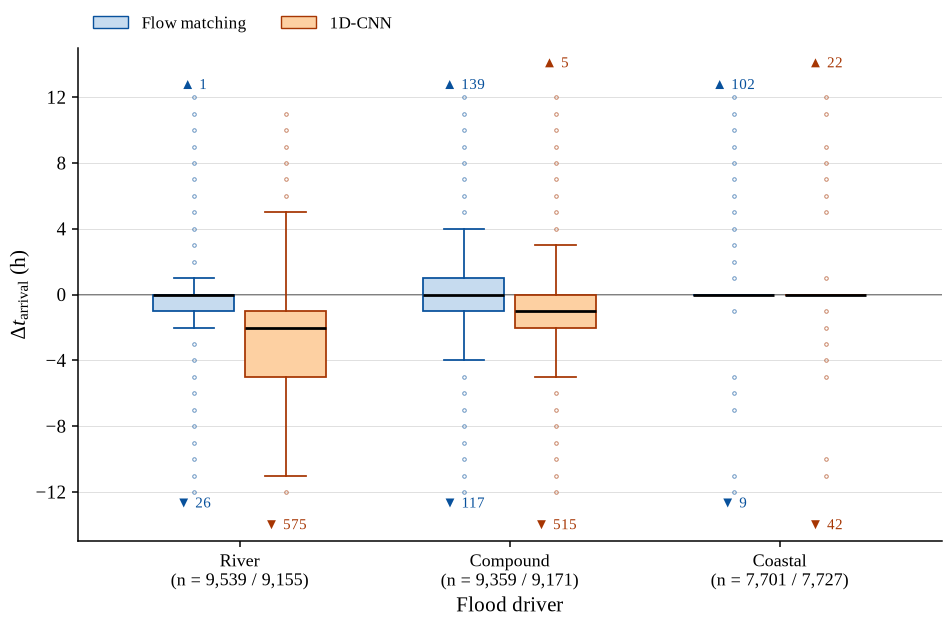

Flow matching Coastal  n =  7,701  median +0 h  IQR +0 to +0 h  within 1 h 91%  beyond +-12 h 111
Flow matching Compound n =  9,359  median +0 h  IQR -1 to +1 h  within 1 h 64%  beyond +-12 h 256
Flow matching River    n =  9,539  median +0 h  IQR -1 to +0 h  within 1 h 83%  beyond +-12 h 27
1D-CNN        Coastal  n =  7,727  median +0 h  IQR +0 to +0 h  within 1 h 88%  beyond +-12 h 64
1D-CNN        Compound n =  9,171  median -1 h  IQR -2 to +0 h  within 1 h 53%  beyond +-12 h 520
1D-CNN        River    n =  9,155  median -2 h  IQR -5 to -1 h  within 1 h 26%  beyond +-12 h 575


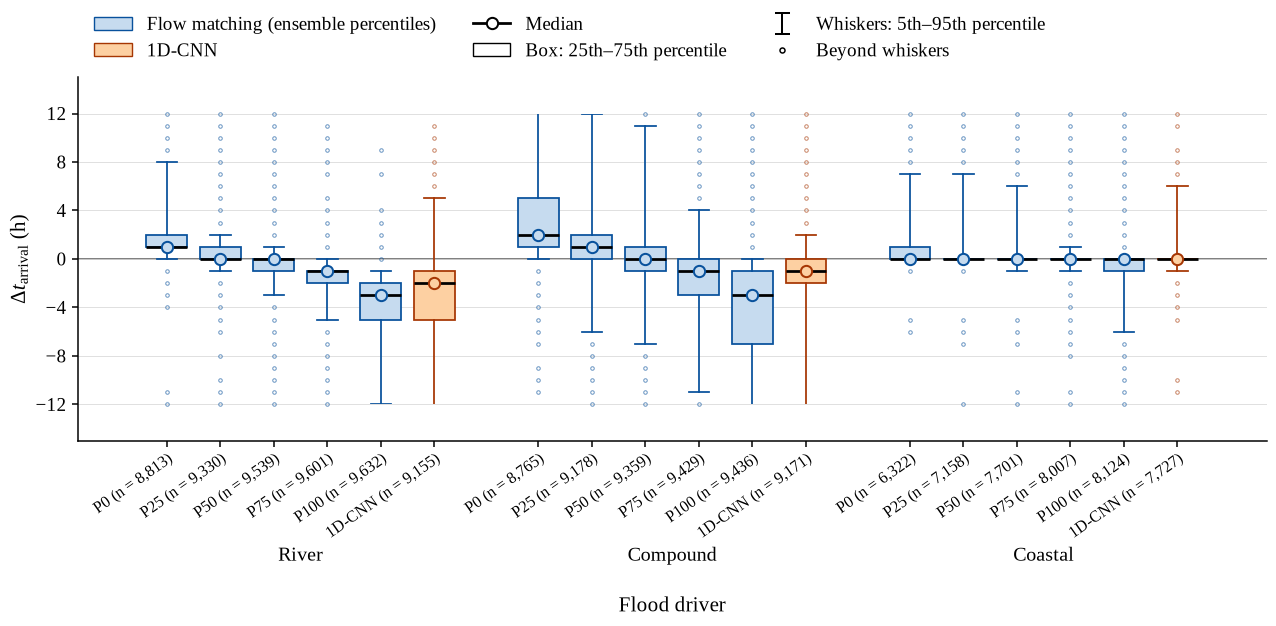

Flood arrival time difference over each forecast's own hits; first 4 h dropped
                       n median [IQR] (h) within 1 h beyond ±12 h
Driver   Forecast                                                
River    FM P0     8,813      +1 [+1, +2]        61%            8
Compound FM P0     8,765      +2 [+1, +5]        42%          890
Coastal  FM P0     6,322      +0 [+0, +1]        85%          171
River    FM P25    9,330      +0 [+0, +1]        87%            5
Compound FM P25    9,178      +1 [+0, +2]        62%          357
Coastal  FM P25    7,158      +0 [+0, +0]        88%          147
River    FM P50    9,539      +0 [-1, +0]        83%           27
Compound FM P50    9,359      +0 [-1, +1]        64%          256
Coastal  FM P50    7,701      +0 [+0, +0]        91%          111
River    FM P75    9,601      -1 [-2, -1]        56%           32
Compound FM P75    9,429      -1 [-3, +0]        58%          365
Coastal  FM P75    8,007      +0 [+0, +0]        92%           

In [138]:
#Box plot of onset error
#
# Flood arrival time difference per house, pooled by flood driver, both models
# side by side: first exposed hour in the model minus the first in the
# simulation (the reference), warm-up excluded; from model_scores in the table
# cell above. Each model is timed on the houses it identified correctly (its
# hits: wet in the reference and flooded by that model), so n differs between
# the two; houses a model misses are for the hit rate.
#
# paired_boxes draws this layout for any per-house difference (Figure 3 below
# uses it too). Box = middle 50% of houses, line = median, whiskers = 1.5 x IQR,
# hollow markers = values with houses beyond them. The axis shows +-limit so the
# boxes are readable; the number of houses beyond it is written at the edge.
# Every statistic still uses all houses: only the view is limited.
Y_LIMIT_H = 12
# offset: the box's place beside the driver tick; count_row: how far beyond the
# window its count of cut-off houses sits, staggered so the two never collide.
MODEL_STYLE = {"flow_matching": dict(face=FILL, edge=EDGE, offset=-0.17, count_row=1.06),
               "cnn1d": dict(face="#FDD0A2", edge="#A63603", offset=0.17, count_row=1.17)}


def draw_box(ax, x_box, values, style, limit, width=0.3, outliers=True, counts=True, median_marker=False,
             whis=1.5):
    """One box of per-house ``values`` at ``x_box``, cropped to +-``limit``: box,
    median, whiskers (``whis``: 1.5 x IQR by default, or a (low, high) pair of
    percentiles such as (5, 95)); with ``outliers``, the values beyond the
    whiskers inside the window; with ``counts``, the count of houses beyond the
    window at its edge (left out where many boxes share a driver, to keep the
    figure readable).
    ``median_marker``: a dot in the box's colour at the median, so a box whose
    quartiles coincide (a line, e.g. every house exact to the hour) stays visible."""
    box = ax.boxplot(values, positions=[x_box], widths=width, patch_artist=True, showfliers=False, whis=whis,
                     boxprops=dict(facecolor=style["face"], edgecolor=style["edge"], lw=0.7 * _SCALE),
                     medianprops=dict(color="black", lw=1.1 * _SCALE),
                     whiskerprops=dict(color=style["edge"], lw=0.7 * _SCALE),
                     capprops=dict(color=style["edge"], lw=0.7 * _SCALE))
    # Boxes and whiskers stop at the window edge; beyond it only the count speaks.
    window = plt.Rectangle((-10, -limit), 20, 2 * limit, transform=ax.transData)
    for artist in (a for artists in box.values() for a in artists):
        artist.set_clip_path(window)
    if median_marker:
        ax.plot([x_box], [np.median(values)], "o", ms=4.5 * _SCALE, markerfacecolor=style["face"],
                markeredgecolor=style["edge"], markeredgewidth=0.8 * _SCALE, zorder=4)
    # Houses beyond the whiskers, drawn only inside the window (one marker per
    # value); those beyond the window are counted at its edge.
    if isinstance(whis, (tuple, list)):
        low, high = np.percentile(values, whis)
    else:
        q1, q3 = np.percentile(values, [25, 75])
        low = values[values >= q1 - whis * (q3 - q1)].min()
        high = values[values <= q3 + whis * (q3 - q1)].max()
    beyond_whiskers = np.unique(values[((values < low) | (values > high)) & (np.abs(values) <= limit)])
    if outliers:
        ax.plot(np.full(len(beyond_whiskers), x_box), beyond_whiskers, "o", markersize=1.4 * _SCALE,
                markerfacecolor="none", markeredgecolor=style["edge"], markeredgewidth=0.4 * _SCALE, alpha=0.6)
    if not counts:
        return
    row = limit * style["count_row"]
    for n_beyond, edge, arrow in [((values > limit).sum(), row, "\u25b2"),
                                  ((values < -limit).sum(), -row, "\u25bc")]:
        if n_beyond:
            # White behind the count, so a box or whisker running past the
            # window does not cross it.
            ax.text(x_box, edge, f"{arrow} {n_beyond}", ha="center", va="center",
                    fontsize=BASE_FONT_PT - 3.5, color=style["edge"], zorder=5,
                    bbox=dict(facecolor="white", edgecolor="none", pad=0.6))


def driver_axis(ax, limit, tick_step):
    """The driver x axis, the zero line and the +-limit window shared by these plots."""
    ax.set_xlim(-0.6, len(regimes) - 0.4)
    ax.set_xlabel("Flood driver")
    ax.axhline(0, color="0.35", lw=0.6 * _SCALE, zorder=0)
    ax.set_ylim(-limit * 1.25, limit * 1.25)
    ax.set_yticks(np.arange(-limit, limit + tick_step / 2, tick_step))
    style_axes(ax)


def paired_boxes(ax, column, limit, tick_step, houses=("hit",), show_counts=True):
    """Both models' per-house ``column`` by driver on ``ax``, cropped to
    +-``limit``. ``houses``: the exposure outcomes scored (hits for timing; hits
    and misses for peak depth, as a miss has a depth but no time).
    ``show_counts``: put the houses per box under each driver name."""
    counts = {}
    for model, style in MODEL_STYLE.items():
        scores = model_scores[model]
        scores = scores[scores["exposure_outcome"].isin(houses)].dropna(subset=[column])
        for x, regime in enumerate(regimes):
            values = scores.loc[scores["scenario_id"].map(regime_of) == regime, column].to_numpy()
            counts[(model, regime)] = len(values)
            draw_box(ax, x + style["offset"], values, style, limit)

    ax.set_xticks(range(len(regimes)))
    def n_label(r):
        n_fm, n_cnn = counts[("flow_matching", r)], counts[("cnn1d", r)]
        return f"n = {n_fm:,}" if n_fm == n_cnn else f"n = {n_fm:,} / {n_cnn:,}"
    ax.set_xticklabels([f"{SHORT_NAMES[r]}\n({n_label(r)})" if show_counts else SHORT_NAMES[r]
                        for r in regimes], fontsize=BASE_FONT_PT - 1.5)
    driver_axis(ax, limit, tick_step)
    return counts


def model_legend(target, **kwargs):
    """The two models' box colours, as a legend on ``target`` (an axis or the figure)."""
    target.legend(handles=[plt.matplotlib.patches.Patch(facecolor=s["face"], edgecolor=s["edge"],
                                                        label=MODEL_LABELS[m])
                           for m, s in MODEL_STYLE.items()],
                  frameon=False, fontsize=BASE_FONT_PT - 2, ncol=2, **kwargs)


fig, ax = plt.subplots(figsize=(FIG_WIDTH_IN * 0.75, FIG_WIDTH_IN * 0.5))
paired_boxes(ax, "onset_error_h", Y_LIMIT_H, 4, houses=("hit",))
ax.set_ylabel("$\\Delta t_{\\mathrm{arrival}}$ (h)")
model_legend(ax, loc="lower left", bbox_to_anchor=(0, 1.0))

fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(os.path.join(FIG_DIR, f"fig_onset_error_by_driver.{ext}"), dpi=600)
plt.show()

for model in MODEL_STYLE:
    onset = model_scores[model].dropna(subset=["onset_error_h"])
    for regime, values in onset.groupby(onset["scenario_id"].map(regime_of))["onset_error_h"]:
        print(f"{MODEL_LABELS[model]:13s} {SHORT_NAMES[regime]:8s} n = {len(values):6,}  median {values.median():+.0f} h  "
              f"IQR {values.quantile(.25):+.0f} to {values.quantile(.75):+.0f} h  within 1 h {(values.abs() <= 1).mean():.0%}  "
              f"beyond +-{Y_LIMIT_H} h {(values.abs() > Y_LIMIT_H).sum()}")

# The same, with flow matching at five percentiles of its ensemble: each
# percentile's depth series scored as a single forecast (building_event_scores),
# its arrival time against the simulation's, over that series' own hits. Warning
# on the max (any member) arrives earliest, on the min (every member) latest.
# Boxes (25th-75th percentile of houses), whiskers at the 5th and 95th percentile
# (90% of houses between them), and the houses beyond, with a dot at each median so
# boxes flattened to a line (coastal: most houses exact to the hour) stay
# visible; the numbers of houses beyond the +-12 h window are in the printed
# table below rather than on the figure.
# All five in the flow-matching colour: the labels under the boxes tell them apart.
ARRIVAL_SERIES = {"depth_min": "FM P0", "depth_p25": "FM P25", "depth_median": "FM P50",
                  "depth_p75": "FM P75", "depth_max": "FM P100"}
fm_percentile_scores = building_event_scores(RUN_CONFIGS["flow_matching"], events=events,
                                             forecast_columns=list(ARRIVAL_SERIES))
series = [(label, fm_percentile_scores[column], MODEL_STYLE["flow_matching"])
          for column, label in ARRIVAL_SERIES.items()]
series.append((MODEL_LABELS["cnn1d"], model_scores["cnn1d"], MODEL_STYLE["cnn1d"]))
offsets = np.linspace(-0.36, 0.36, len(series))

fig, ax = plt.subplots(figsize=(FIG_WIDTH_IN, FIG_WIDTH_IN * 0.5))
summary = {}
for i, (label, scores, style) in enumerate(series):
    hits = scores[scores["exposure_outcome"] == "hit"].dropna(subset=["onset_error_h"])
    style = {**style, "count_row": (1.06, 1.17)[i % 2]}   # counts staggered so neighbours do not collide
    for x, regime in enumerate(regimes):
        values = hits.loc[hits["scenario_id"].map(regime_of) == regime, "onset_error_h"].to_numpy()
        draw_box(ax, x + offsets[i], values, style, Y_LIMIT_H, width=0.11, counts=False, median_marker=True,
                 whis=(5, 95))
        summary[(SHORT_NAMES[regime], label)] = {
            "n": f"{len(values):,}",
            "median [IQR] (h)": f"{np.median(values):+.0f} [{np.percentile(values, 25):+.0f}, {np.percentile(values, 75):+.0f}]",
            "within 1 h": f"{(np.abs(values) <= 1).mean():.0%}",
            f"beyond \u00b1{Y_LIMIT_H} h": int((np.abs(values) > Y_LIMIT_H).sum())}
driver_axis(ax, Y_LIMIT_H, 4)
# Each box labelled under itself, tilted, with its number of houses (its own
# hits, so n differs between boxes); the driver named below its group of boxes,
# placed under the lowest tilted label.
ax.set_xticks([x + offset for x in range(len(regimes)) for offset in offsets])
ax.set_xticklabels([f"{label.replace('FM ', '')} (n = {summary[(SHORT_NAMES[regime], label)]['n']})"
                    for regime in regimes for label, _, _ in series],
                   fontsize=BASE_FONT_PT - 3, rotation=35, ha="right", rotation_mode="anchor")
fig.canvas.draw()
label_depth_pt = (ax.get_window_extent().y0 - min(t.get_window_extent().y0 for t in ax.get_xticklabels())) * 72 / fig.dpi
below_labels = ax.get_xaxis_transform() + plt.matplotlib.transforms.ScaledTranslation(
    0, -(label_depth_pt + 4) / 72, fig.dpi_scale_trans)
for x, regime in enumerate(regimes):
    ax.text(x, 0, SHORT_NAMES[regime], transform=below_labels, ha="center", va="top", fontsize=BASE_FONT_PT)
ax.set_xlabel("Flood driver", labelpad=22 * _SCALE)
ax.set_ylabel("$\\Delta t_{\\mathrm{arrival}}$ (h)")
# Legend: the two models' colours, then what the parts of a box mean. The
# whisker entry is drawn as a small capped vertical line.
class WhiskerHandler(plt.matplotlib.legend_handler.HandlerBase):
    def create_artists(self, legend, handle, xdescent, ydescent, width, height, fontsize, trans):
        x, low, high = width / 2 - xdescent, -ydescent - 0.3 * height, height * 1.3 - ydescent
        kw = dict(color="black", lw=0.8 * _SCALE, transform=trans)
        cap = width * 0.18
        return [plt.matplotlib.lines.Line2D([x, x], [low, high], **kw),
                plt.matplotlib.lines.Line2D([x - cap, x + cap], [low, low], **kw),
                plt.matplotlib.lines.Line2D([x - cap, x + cap], [high, high], **kw)]

Patch, Line2D = plt.matplotlib.patches.Patch, plt.matplotlib.lines.Line2D
whisker_handle = object()
handles = [Patch(facecolor=MODEL_STYLE["flow_matching"]["face"], edgecolor=MODEL_STYLE["flow_matching"]["edge"],
                 label="Flow matching (ensemble percentiles)"),
           Patch(facecolor=MODEL_STYLE["cnn1d"]["face"], edgecolor=MODEL_STYLE["cnn1d"]["edge"],
                 label=MODEL_LABELS["cnn1d"]),
           Line2D([], [], color="black", lw=1.1 * _SCALE, marker="o", ms=4.5 * _SCALE, markerfacecolor="white",
                  markeredgecolor="black", markeredgewidth=0.8 * _SCALE, label="Median"),
           Patch(facecolor="white", edgecolor="black", label="Box: 25th–75th percentile"),
           whisker_handle,
           Line2D([], [], ls="none", marker="o", ms=2 * _SCALE, markerfacecolor="none",
                  markeredgecolor="black", markeredgewidth=0.6 * _SCALE, label="Beyond whiskers")]
labels = [h.get_label() if h is not whisker_handle else "Whiskers: 5th–95th percentile" for h in handles]
ax.legend(handles, labels, handler_map={whisker_handle: WhiskerHandler()}, frameon=False,
          fontsize=BASE_FONT_PT - 1, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0))
fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(os.path.join(FIG_DIR, f"fig_onset_error_by_driver_percentiles.{ext}"), dpi=600)
plt.show()

print(f"Flood arrival time difference over each forecast's own hits; first {SKIP_FIRST_STEPS} h dropped")
print(pd.DataFrame(summary).T.rename_axis(["Driver", "Forecast"]).to_string())


In [137]:
# Figure 3: peak-depth, peak-time and flood-arrival-time difference by flood
# driver, both models side by side, one value per building per event.
#
# Delta d_peak = model peak depth - simulation peak depth at each house: the
# peak of the model's ensemble-median depth minus the peak of the hydrodynamic
# simulation's depth, each the highest hour of its own series and both read
# through the same footprint summary; over the houses the simulation floods
# (hits and misses). Delta t_peak = model peak hour - simulation peak hour, and
# Delta .
model_legend(fig, loc="upper center", bbox_to_anchor=(0.5, 1.0))

fig.tight_layout(w_pad=2, rect=(0, 0, 1, 0.93))
for ext in ("pdf", "png"):
    fig.savefig(os.path.join(FIG_DIR, f"fig_peak_onset_error_by_driver.{ext}"), dpi=600)
plt.show()

for column, label, limit, _, houses in panels:
    for model in MODEL_STYLE:
        scores = model_scores[model]
        scores = scores[scores["exposure_outcome"].isin(houses)].dropna(subset=[column])
        for regime, values in scores.groupby(scores["scenario_id"].map(regime_of))[column]:
            print(f"{column:18s} {MODEL_LABELS[model]:13s} {SHORT_NAMES[regime]:8s} n = {len(values):6,}  "
                  f"median {values.median():+.3f}  IQR {values.quantile(.25):+.3f} to {values.quantile(.75):+.3f}  "
                  f"beyond +-{limit} {(values.abs() > limit).sum()}")


ValueError: not enough values to unpack (expected 5, got 4)

5556 houses in the computational domain; first 4 h of each event dropped
                     Simulation                         Flow matching             1D-CNN
               Inundated houses Fraction inundated Peak depth MAE (m) Peak depth MAE (m)
Driver   Event                                                                          
River    3                4,217              75.9%              0.071              0.328
         43                   2               0.0%              0.070              0.040
         64                 307               5.5%              0.105              0.124
         83               5,110              92.0%              0.067              0.580
Compound 13               3,124              56.2%              0.058              0.318
         37                 843              15.2%              0.051              0.107
         54                   7               0.1%              0.046              0.076
         91                 357      

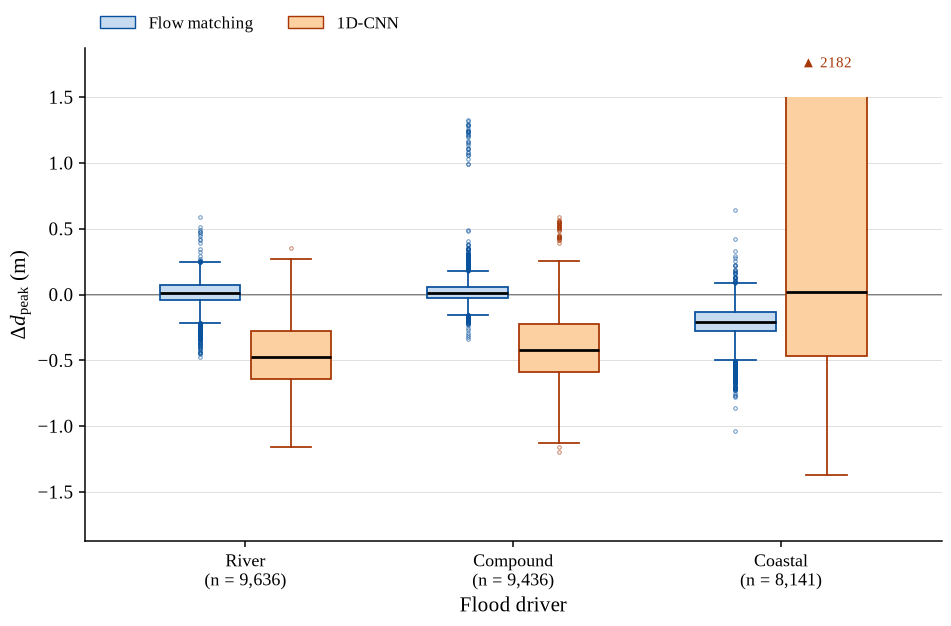

              n Flow matching: median [IQR] (m) Flow matching: beyond ±1.5 m 1D-CNN: median [IQR] (m) 1D-CNN: beyond ±1.5 m
River     9,636         +0.015 [-0.042, +0.073]                            0  -0.473 [-0.643, -0.276]                     0
Compound  9,436         +0.015 [-0.028, +0.055]                            0  -0.418 [-0.587, -0.220]                     0
Coastal   8,141         -0.206 [-0.279, -0.131]                            0  +0.019 [-0.466, +1.599]                  2182


In [127]:
# Table: peak flood depth MAE per event, over the houses wet in the reference.
#
# Inundated = the simulation's (reference) peak depth at the house exceeds 0.05 m
# after the warm-up; their fraction is of all the houses in the computational
# domain. Peak depth MAE = mean of |model peak depth - simulation peak depth|,
# each the highest hour of its own series, over those same houses for both
# models (a house a model misses is scored with the depth it gave it), so the
# two models are scored on the same houses. From model_scores in the event table
# cell.
columns = {}
for model in RUN_CONFIGS:
    scores = model_scores[model]
    for event, event_scores in scores.groupby("scenario_id"):
        inundated = event_scores[event_scores["exposure_outcome"].isin(["hit", "miss"])]
        columns.setdefault(("Simulation", "Inundated houses"), {})[event] = len(inundated)
        columns.setdefault(("Simulation", "Fraction inundated"), {})[event] = len(inundated) / len(event_scores)
        columns.setdefault((MODEL_LABELS[model], "Peak depth MAE (m)"), {})[event] = (
            inundated["peak_depth_error"].abs().mean() if len(inundated) else np.nan)

depth_table = pd.DataFrame(columns).reindex(events)
depth_table.columns = pd.MultiIndex.from_tuples(depth_table.columns)
depth_table = depth_table[["Simulation"] + list(MODEL_LABELS.values())]
depth_table.index = pd.MultiIndex.from_tuples(
    [(SHORT_NAMES[regime_of[event]], event) for event in events], names=["Driver", "Event"])
print(f"{len(event_scores)} houses in the computational domain; first {SKIP_FIRST_STEPS} h of each event dropped")
print(depth_table.to_string(formatters={
    ("Simulation", "Inundated houses"): "{:,}".format,
    ("Simulation", "Fraction inundated"): "{:.1%}".format,
    **{(label, "Peak depth MAE (m)"): "{:.3f}".format for label in MODEL_LABELS.values()}}))

# Box plot of the peak depth residual, Delta d_peak = model peak depth -
# simulation peak depth, per house over the same houses as the MAE (wet in the
# reference: hits and misses, the same houses for both models),
# pooled by driver, both models side by side; drawn with paired_boxes (the flood
# arrival cell above), cropped to +-DEPTH_LIMIT_M with the houses beyond counted.
DEPTH_LIMIT_M = 1.5
fig, ax = plt.subplots(figsize=(FIG_WIDTH_IN * 0.75, FIG_WIDTH_IN * 0.5))
paired_boxes(ax, "peak_depth_error", DEPTH_LIMIT_M, 0.5, houses=("hit", "miss"))
ax.set_ylabel("$\\Delta d_{\\mathrm{peak}}$ (m)")
model_legend(ax, loc="lower left", bbox_to_anchor=(0, 1.0))
fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(os.path.join(FIG_DIR, f"fig_peak_depth_difference_by_driver.{ext}"), dpi=600)
plt.show()

# Per driver: the houses (the same for both models), and each model's median
# [IQR] difference and the houses beyond the plotted window.
summary = {}
for model in RUN_CONFIGS:
    wet = model_scores[model][model_scores[model]["exposure_outcome"].isin(["hit", "miss"])]
    for regime, values in wet.groupby(wet["scenario_id"].map(regime_of))["peak_depth_error"]:
        row = summary.setdefault(SHORT_NAMES[regime], {"n": f"{len(values):,}"})
        row[f"{MODEL_LABELS[model]}: median [IQR] (m)"] = (
            f"{values.median():+.3f} [{values.quantile(.25):+.3f}, {values.quantile(.75):+.3f}]")
        row[f"{MODEL_LABELS[model]}: beyond \u00b1{DEPTH_LIMIT_M:g} m"] = int((values.abs() > DEPTH_LIMIT_M).sum())
print(pd.DataFrame(summary).T.reindex([SHORT_NAMES[r] for r in regimes]).to_string())


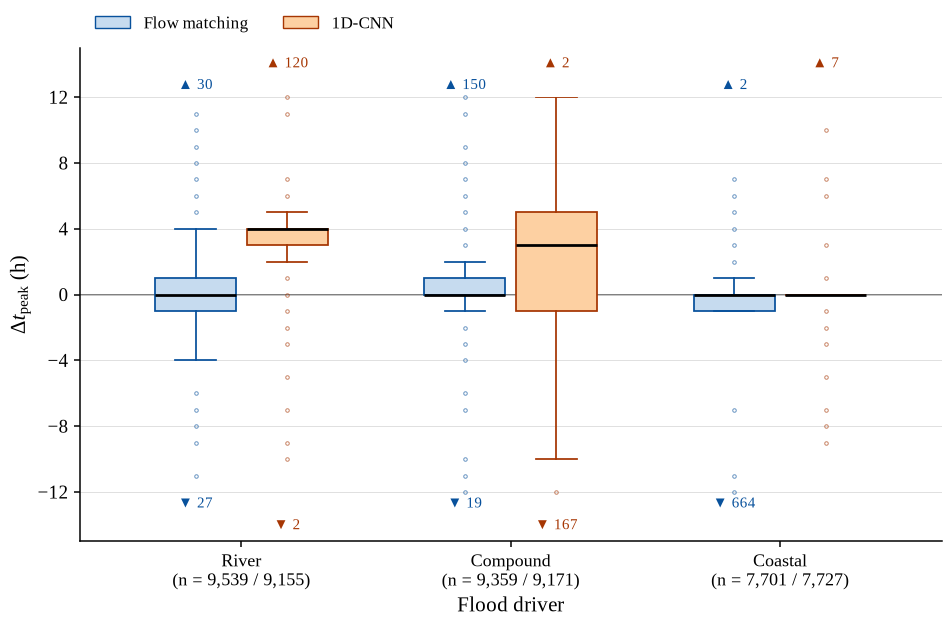

         Flow matching: n Flow matching: median [IQR] (h) Flow matching: within 1 h Flow matching: beyond ±12 h 1D-CNN: n 1D-CNN: median [IQR] (h) 1D-CNN: within 1 h 1D-CNN: beyond ±12 h
River               9,539                     +0 [-1, +1]                       88%                          57     9,155              +4 [+3, +4]                16%                  122
Compound            9,359                     +0 [+0, +1]                       86%                         169     9,171              +3 [-1, +5]                32%                  169
Coastal             7,701                     +0 [-1, +0]                       82%                         666     7,727              +0 [+0, +0]                98%                    7


In [128]:
# Box plot of the peak time difference, Delta t_peak = hour of the model's peak
# depth minus the hour of the simulation's (the reference), per house, pooled by
# driver, both models side by side. A peak time exists only where the model
# floods the house, so each model is timed on the houses it identified correctly
# (its hits) and n differs between the two, as for the flood arrival time.
# Drawn with paired_boxes (the flood arrival cell), cropped to +-PEAK_LIMIT_H.
PEAK_LIMIT_H = 12
fig, ax = plt.subplots(figsize=(FIG_WIDTH_IN * 0.75, FIG_WIDTH_IN * 0.5))
paired_boxes(ax, "peak_time_error_h", PEAK_LIMIT_H, 4, houses=("hit",))
ax.set_ylabel("$\\Delta t_{\\mathrm{peak}}$ (h)")
model_legend(ax, loc="lower left", bbox_to_anchor=(0, 1.0))
fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(os.path.join(FIG_DIR, f"fig_peak_time_difference_by_driver.{ext}"), dpi=600)
plt.show()

# Per driver and model: the houses timed, the median [IQR] difference, the share
# within one hour and the houses beyond the plotted window.
summary = {}
for model in RUN_CONFIGS:
    hits = model_scores[model][model_scores[model]["exposure_outcome"] == "hit"].dropna(subset=["peak_time_error_h"])
    for regime, values in hits.groupby(hits["scenario_id"].map(regime_of))["peak_time_error_h"]:
        row = summary.setdefault(SHORT_NAMES[regime], {})
        label = MODEL_LABELS[model]
        row[f"{label}: n"] = f"{len(values):,}"
        row[f"{label}: median [IQR] (h)"] = (
            f"{values.median():+.0f} [{values.quantile(.25):+.0f}, {values.quantile(.75):+.0f}]")
        row[f"{label}: within 1 h"] = f"{(values.abs() <= 1).mean():.0%}"
        row[f"{label}: beyond \u00b1{PEAK_LIMIT_H} h"] = int((values.abs() > PEAK_LIMIT_H).sum())
print(pd.DataFrame(summary).T.reindex([SHORT_NAMES[r] for r in regimes]).to_string())


In [6]:
# Probabilistic forecasts
#
# Detection when warning on each percentile of the flow-matching ensemble
# (percentile_event_metrics.csv, written by the validation): for each house and
# hour the members' depths are read at the percentile, that series is scored as
# a single forecast, and a house counts as inundated if it exceeds 0.05 m at any
# hour after the warm-up. min = warn only if every member floods the house
# (confident); max = warn if any member does (cautious). Counts are summed over
# each driver's events. The 1D-CNN has a single forecast, so one value (flat
# lines), from model_scores with the same warm-up.
PERCENTILE_ORDER = ["min", "p25", "median", "p75", "max"]
PERCENTILE_LABELS = {"min": "P0", "p25": "P25", "median": "P50", "p75": "P75", "max": "P100"}

percentiles = pd.read_csv(os.path.join(VALIDATION_RESULTS_DIR, RUN_CONFIGS["flow_matching"],
                                       "percentile_event_metrics.csv"))
# A re-run of an event appends its rows again; keep the latest.
percentiles = percentiles.drop_duplicates(["scenario_id", "percentile"], keep="last")
assert (percentiles["warm_up_h"] == SKIP_FIRST_STEPS).all(), "percentile metrics use a different warm-up"
percentiles["regime"] = percentiles["scenario_id"].map(regime_of)
pooled = percentiles.groupby(["regime", "percentile"])[["hits", "misses", "false_alarms"]].sum()
pooled["hit_rate"] = pooled["hits"] / (pooled["hits"] + pooled["misses"])
pooled["csi"] = pooled["hits"] / (pooled["hits"] + pooled["misses"] + pooled["false_alarms"])

cnn = model_scores["cnn1d"].assign(regime=model_scores["cnn1d"]["scenario_id"].map(regime_of))
cnn = cnn.groupby("regime")["exposure_outcome"].value_counts().unstack(fill_value=0)
cnn_hit_rate = cnn["hit"] / (cnn["hit"] + cnn["miss"])
cnn_csi = cnn["hit"] / (cnn["hit"] + cnn["miss"] + cnn["false_alarm"])

fm_colour, cnn_colour = MODEL_STYLE["flow_matching"]["edge"], MODEL_STYLE["cnn1d"]["edge"]
fig, axes = plt.subplots(1, len(regimes), figsize=(FIG_WIDTH_IN, FIG_WIDTH_IN * 0.36), sharey=True)
x = np.arange(len(PERCENTILE_ORDER))
for i, (ax, regime) in enumerate(zip(axes, regimes)):
    scores = pooled.loc[regime].reindex(PERCENTILE_ORDER)
    ax.plot(x, scores["hit_rate"], "o-", color=fm_colour, lw=1.2 * _SCALE, ms=3.5 * _SCALE, label="Flow matching: hit rate")
    ax.plot(x, scores["csi"], "s--", color=fm_colour, lw=1.2 * _SCALE, ms=3.5 * _SCALE, label="Flow matching: CSI")
    ax.axhline(cnn_hit_rate[regime], color=cnn_colour, lw=1.0 * _SCALE, label="1D-CNN: hit rate")
    ax.axhline(cnn_csi[regime], color=cnn_colour, lw=1.0 * _SCALE, ls="--", label="1D-CNN: CSI")
    ax.set_xticks(x)
    ax.set_xticklabels([PERCENTILE_LABELS[p] for p in PERCENTILE_ORDER], fontsize=BASE_FONT_PT - 1.5)
    ax.set_xlabel("Ensemble percentile")
    ax.tick_params(labelleft=True)   # values on every panel, not only the first
    if i == 0:
        ax.set_ylabel("Hit rate, CSI")
    panel_title(ax, chr(97 + i), SHORT_NAMES[regime], pad=6)
    style_axes(ax)
axes[0].set_ylim(top=1.01)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.0), ncol=4, frameon=False,
           fontsize=BASE_FONT_PT - 2)
fig.tight_layout(w_pad=1.5, rect=(0, 0, 1, 0.9))
for ext in ("pdf", "png"):
    fig.savefig(os.path.join(FIG_DIR, f"fig_detection_by_percentile.{ext}"), dpi=600)
plt.show()

table = pooled[["hit_rate", "false_alarms", "csi"]].copy()
table.index = pd.MultiIndex.from_tuples([(SHORT_NAMES[r], PERCENTILE_LABELS[p]) for r, p in table.index],
                                        names=["Driver", "Ensemble percentile"])
for regime in regimes:
    table.loc[(SHORT_NAMES[regime], "1D-CNN"), :] = [cnn_hit_rate[regime], cnn.loc[regime, "false_alarm"], cnn_csi[regime]]
table = table.reindex([(SHORT_NAMES[r], p) for r in regimes
                       for p in ["1D-CNN"] + [PERCENTILE_LABELS[q] for q in PERCENTILE_ORDER]])
print(f"Detection over each event, summed by driver; first {SKIP_FIRST_STEPS} h dropped")
print(table.to_string(formatters={"hit_rate": "{:.3f}".format, "csi": "{:.3f}".format,
                                  "false_alarms": lambda v: f"{int(v):,}"}))


Detection over each event, summed by driver; first 4 h dropped
                             hit_rate false_alarms   csi
Driver   Ensemble percentile                            
River    1D-CNN                 0.950        2,278 0.768
         P0                     0.915           25 0.912
         P25                    0.968          176 0.951
         P50                    0.990        1,141 0.885
         P75                    0.996        2,274 0.806
         P100                   1.000        5,356 0.642
Compound 1D-CNN                 0.972        3,162 0.728
         P0                     0.929          152 0.914
         P25                    0.973        1,361 0.850
         P50                    0.992        2,796 0.765
         P75                    0.999        4,901 0.658
         P100                   1.000        8,221 0.534
Coastal  1D-CNN                 0.949        1,093 0.837
         P0                     0.777           11 0.776
         P25             